# Taiwan Housing Price-Driver Analysis

**Question:** What drives residential price-per-ping in Taipei and New Taipei, and by how much?

This is a regression-based price-driver decomposition (not latent-variable factor
analysis), built on 實價登錄 (official MOI real-price registration) data. Two
complementary models -- OLS and LightGBM + SHAP -- are fit and reconciled. The
goal is **explanation**, not prediction; metrics below establish that the models
are trustworthy enough to interpret, not a forecasting target.

**Pre-committed headline questions** (see `../../drivers_design_v3.md` -- committed
*before* this analysis, so the headline can't be cherry-picked after seeing results):

1. Management-organization premium, controlling for area/age/type/district -- is
   it a real premium, or a proxy for new/large buildings?
2. Is the building-age effect monotonic, or does it flatten/reverse for old
   buildings (especially 透天厝)?
3. How much of the district price gap survives controlling for age/type/area --
   structural, or just compositional?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.api as sm
import lightgbm as lgb
import shap
from sklearn.metrics import r2_score, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

import sys
sys.path.insert(0, '../src')
import db

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Several charts label districts/building types in Chinese (e.g. 大安區,
# 透天厝). matplotlib's default font has no CJK glyphs and silently renders
# them as empty boxes -- this was missed in the first pass because the
# charts were never actually opened and looked at, only checked for file
# existence. Pick whichever CJK-capable font is actually installed; warn
# loudly (not silently) if none is found, rather than reproducing the bug
# on some future machine.
_cjk_candidates = ['Microsoft JhengHei', 'Microsoft YaHei', 'PingFang TC',
                    'Noto Sans CJK TC', 'Noto Sans TC', 'SimHei', 'Heiti TC',
                    'WenQuanYi Zen Hei']
_available_fonts = {f.name for f in fm.fontManager.ttflist}
_cjk_font = next((f for f in _cjk_candidates if f in _available_fonts), None)
if _cjk_font:
    plt.rcParams['font.sans-serif'] = [_cjk_font] + plt.rcParams['font.sans-serif']
    print(f'Using CJK font: {_cjk_font}')
else:
    print('WARNING: no CJK-capable font found -- Chinese chart labels will '
          'render as empty boxes. Install one (e.g. fonts-noto-cjk on Debian/Ubuntu).')
plt.rcParams['axes.unicode_minus'] = False
ASSETS_DIR = '../app/assets'
import os
os.makedirs(ASSETS_DIR, exist_ok=True)


Using CJK font: Microsoft JhengHei


## 1. Load data and scope the modeling sample

`fct_transactions` applies every M1 filter **plus** the structural-presale
filter: rows where the completion date is after the transaction date (the
building did not exist at sale) are quarantined upstream to `rej_transactions`
with reason `presale_structural`. So no presale/negative-age handling is
needed here -- it's already done in the pipeline.

The model uses **complete cases**: it drops the ~2.7% of rows with a missing
completion date (null `building_age`) and the handful missing `total_floors`.
Those are valid existing-home sales -- the dashboard keeps them -- but a
regression on age cannot use a null age. `floor_ratio` for whole-building
sales (almost all 透天厝, the type Q2 asks about by name) is imputed to 1.0
rather than dropped, so those townhouses stay in the sample.


In [2]:
df = pd.read_sql('SELECT * FROM fct_transactions', db.get_engine())
n_fct = len(df)
print('rows in fct_transactions:', n_fct)

# Structural presale is filtered upstream in the pipeline (clean.py ->
# rej_transactions, reason 'presale_structural'), so no negative ages remain.
assert (df['building_age'] < 0).sum() == 0, 'unexpected negative building_age in fct'

# Complete-case modeling: drop rows missing a model feature. building_age is
# null for ~2.7% (blank completion date) -- valid sales the dashboard keeps,
# but a regression on age can't use them.
before = len(df)
df = df.dropna(subset=['building_age', 'total_floors']).copy()
print(f'dropped {before - len(df)} rows missing building_age/total_floors (complete-case)')

df['floor_ratio'] = df['floor_ratio'].fillna(1.0)  # whole-building -> 1.0

df['txn_date'] = pd.to_datetime(df['txn_date'])
_start = df['txn_date'].min()
df['months_since_start'] = (df['txn_date'].dt.year - _start.year) * 12 + (df['txn_date'].dt.month - _start.month)

df['has_management_int'] = df['has_management'].astype(int)
df['whole_building_int'] = df['whole_building'].astype(int)
df['bundled_parking_int'] = df['bundled_parking'].astype(int)
df['parking_price_is_zero_int'] = df['parking_price_is_zero'].astype(int)

print('modeling sample:', len(df), f"({100*len(df)/n_fct:.1f}% of fct_transactions)")
print('date range:', df['txn_date'].min().date(), 'to', df['txn_date'].max().date())


rows in fct_transactions: 100828
dropped 2774 rows missing building_age/total_floors (complete-case)
modeling sample: 98054 (97.2% of fct_transactions)
date range: 2014-05-21 to 2026-05-30


## 2. EDA

In [3]:
print('=== price_per_ping distribution ===')
print(df['price_per_ping'].describe())


=== price_per_ping distribution ===
count      98,054.0000
mean      554,306.0017
std       253,375.2667
min       119,056.1322
25%       374,274.3802
50%       511,684.2975
75%       686,254.5455
max     1,455,101.6529
Name: price_per_ping, dtype: float64


In [4]:
print('=== median price_per_ping by building_type ===')
print(df.groupby('building_type')['price_per_ping'].median().sort_values(ascending=False))


=== median price_per_ping by building_type ===
building_type
住宅大樓(11層含以上有電梯)   549,833.0579
華廈(10層含以下有電梯)     544,833.0579
公寓(5樓含以下無電梯)      455,438.0165
透天厝               390,667.7686
Name: price_per_ping, dtype: float64


In [5]:
print('=== median price_per_ping by district: top 5 / bottom 5 ===')
by_district = df.groupby('district')['price_per_ping'].median().sort_values(ascending=False)
print(by_district.head(5))
print('...')
print(by_district.tail(5))


=== median price_per_ping by district: top 5 / bottom 5 ===
district
大安區   1,028,942.1488
中正區     928,715.7025
松山區     871,947.1074
信義區     833,423.1405
中山區     800,634.7107
Name: price_per_ping, dtype: float64
...
district
瑞芳區   126,066.1157
萬里區   119,056.1322
石門區   119,056.1322
貢寮區   119,056.1322
雙溪區   119,056.1322
Name: price_per_ping, dtype: float64


In [6]:
print('=== correlation with price_per_ping (numeric features) ===')
print(df[['price_per_ping','building_age','area_ping','floor_level','floor_ratio','rooms','halls','baths']]
      .corr()['price_per_ping'].sort_values(ascending=False))


=== correlation with price_per_ping (numeric features) ===
price_per_ping    1.0000
floor_level       0.0913
area_ping         0.0188
floor_ratio      -0.0623
halls            -0.0978
baths            -0.1045
building_age     -0.1099
rooms            -0.1859
Name: price_per_ping, dtype: float64


### Separability check: `has_management` x `building_type`

Headline question 1's robustness depends on `has_management` not being
near-separable from `building_type` (if it were, the full-model coefficient
would be identified mostly from across-type contrast and could mislead).
Checked here in EDA, then stress-tested directly in Section 3 by estimating
the effect *within* each building type -- a tight full-model CI alone is not
sufficient.


In [7]:
ct = pd.crosstab(df['building_type'], df['has_management'], normalize='index') * 100
print('has_management rate (%) by building_type:')
print(ct.round(1))
print()
print(f"overall has_management rate: {df['has_management'].mean()*100:.1f}%")


has_management rate (%) by building_type:
has_management    False   True 
building_type                  
住宅大樓(11層含以上有電梯)  1.7000 98.3000
公寓(5樓含以下無電梯)    93.4000  6.6000
華廈(10層含以下有電梯)   15.3000 84.7000
透天厝             57.4000 42.6000

overall has_management rate: 68.4%


No category is fully separated (every building_type has both managed and
unmanaged examples), but 住宅大樓 (98.3% managed) and 公寓 (6.6% managed) are
heavily skewed -- exactly the risk flagged in the design doc. Only 透天厝
(42.6% managed) and 華廈 (84.7% managed) carry substantial within-type
contrast. Section 3 stress-tests the effect within each.

## 3. OLS on log(price_per_ping)

Districts and building types one-hot encoded (reference categories: whichever
sorts first alphabetically and gets dropped). Effects reported as `exp(beta)-1`,
not raw beta, since district/type gaps are large (50-100%+ per ping is normal in
this data) and the linear-percent approximation breaks down at that size.
VIF is computed on the continuous predictors only -- a one-hot district block is
structurally near-collinear by construction and would trip VIF without that
restriction, while incorrectly suggesting district dummies should be pruned.


In [8]:
continuous_cols = ['building_age','area_ping','floor_ratio','total_floors',
                    'rooms','halls','baths','months_since_start']
control_cols = ['has_management_int','whole_building_int',
                'bundled_parking_int','parking_price_is_zero_int']

district_dummies = pd.get_dummies(df['district'], prefix='district', drop_first=True)
type_dummies = pd.get_dummies(df['building_type'], prefix='type', drop_first=True)

X = pd.concat([df[continuous_cols + control_cols], district_dummies, type_dummies], axis=1).astype(float)
X = sm.add_constant(X)
y = df['log_price_per_ping'].astype(float)

ols_model = sm.OLS(y, X).fit()
print('R-squared:', ols_model.rsquared)
print('N:', int(ols_model.nobs))


R-squared: 0.7651160620122884
N: 98054


In [9]:
vif_X = sm.add_constant(df[continuous_cols].astype(float))
print('=== VIF on continuous predictors only ===')
for i, col in enumerate(vif_X.columns):
    if col == 'const':
        continue
    print(f'  {col}: {variance_inflation_factor(vif_X.values, i):.2f}')


=== VIF on continuous predictors only ===
  building_age: 1.79
  area_ping: 1.52
  floor_ratio: 1.06
  total_floors: 1.71
  rooms: 2.60
  halls: 1.39
  baths: 2.13
  months_since_start: 1.00


All VIF values are well under 5 (max ~2.6) -- no problematic multicollinearity
among the continuous predictors.

In [10]:
coef = ols_model.params['has_management_int']
se = ols_model.bse['has_management_int']
ci_low, ci_high = ols_model.conf_int().loc['has_management_int']
pval = ols_model.pvalues['has_management_int']

print('=== has_management_int coefficient (Q1) ===')
print(f'  beta = {coef:.4f}, se = {se:.4f}, p = {pval:.2e}')
print(f'  exp(beta)-1 = {np.exp(coef)-1:+.2%}  (95% CI: {np.exp(ci_low)-1:+.2%} to {np.exp(ci_high)-1:+.2%})')


=== has_management_int coefficient (Q1) ===
  beta = -0.0916, se = 0.0031, p = 2.87e-187
  exp(beta)-1 = -8.76%  (95% CI: -9.31% to -8.19%)


The full-model coefficient is tight (p < 1e-180), but tightness is not
robustness here. Because `has_management` is nearly collinear with
`building_type` (Section 2: 98.3% of 住宅大樓 managed, 6.6% of 公寓), this
-8.8% is identified largely from *across-type* contrast. The real test:
does the discount survive *within* a building type that has a genuine mix of
managed and unmanaged units? If it only exists across types, the headline is
an artifact and must be reframed.

### Robustness: `has_management` estimated within each building type

For each building type separately, refit the same model with all controls
except `building_type` (constant within stratum). A stable effect should
reappear within the types that have real managed/unmanaged contrast.

In [11]:
within = []
for bt in df['building_type'].value_counts().index:
    sub = df[df['building_type'] == bt].copy()
    n_mgmt, n_no = int(sub['has_management_int'].sum()), int((~sub['has_management']).sum())
    if n_mgmt < 30 or n_no < 30:
        continue
    dd = pd.get_dummies(sub['district'], prefix='district', drop_first=True)
    # control_cols already contains has_management_int (the variable of interest);
    # building_type is dropped since it is constant within the stratum.
    Xs = sm.add_constant(pd.concat([sub[continuous_cols + control_cols], dd], axis=1).astype(float))
    ms = sm.OLS(sub['log_price_per_ping'].astype(float), Xs).fit()
    b = ms.params['has_management_int']; lo, hi = ms.conf_int().loc['has_management_int']
    within.append({'building_type': bt, 'N': len(sub), 'managed_pct': 100*n_mgmt/len(sub),
                   'effect': np.exp(b)-1, 'ci_low': np.exp(lo)-1, 'ci_high': np.exp(hi)-1, 'p': ms.pvalues['has_management_int']})
within_df = pd.DataFrame(within)
for d in within:
    print(f"{d['building_type'][:18]:20s} N={int(d['N']):6d} managed={float(d['managed_pct']):5.1f}%  "
          f"effect={float(d['effect']):+.1%}  (CI {float(d['ci_low']):+.1%} to {float(d['ci_high']):+.1%})  "
          f"p={float(d['p']):.1e}")


住宅大樓(11層含以上有電梯)      N= 49194 managed= 98.3%  effect=+6.4%  (CI +5.0% to +7.8%)  p=7.9e-20
公寓(5樓含以下無電梯)         N= 27727 managed=  6.6%  effect=-10.3%  (CI -11.4% to -9.2%)  p=6.6e-66
華廈(10層含以下有電梯)        N= 18608 managed= 84.7%  effect=-0.9%  (CI -1.8% to -0.1%)  p=3.7e-02
透天厝                  N=  2525 managed= 42.6%  effect=-8.8%  (CI -12.3% to -5.1%)  p=6.3e-06


The effect is **heterogeneous**, not a single universal discount:

- **透天厝** (most balanced, 42.6% managed) and **公寓** (walk-ups): the
  discount holds strongly, **-8.8%** and **-10.3%** -- so it is *not* a pure
  cross-type artifact. It is a real within-type effect for low-rise housing.
- **華廈** (mid-rise): essentially zero (**-0.9%**).
- **住宅大樓** (high-rise): *flips* to **+6.4%** -- investigated next.

In [12]:
# Why does high-rise flip? Check the age profile of unmanaged 住宅大樓.
hr = df[df['building_type'] == '住宅大樓(11層含以上有電梯)']
prof = hr.groupby('has_management')['building_age'].agg(['count', 'median'])
new_share = hr.groupby('has_management')['building_age'].apply(lambda s: (s <= 2).mean() * 100)
print('住宅大樓 age by management status:')
print(prof)
print()
print('share age <= 2 (brand new):')
print(new_share.round(1))


住宅大樓 age by management status:
                count  median
has_management               
False             840  1.0000
True            48354 15.0000

share age <= 2 (brand new):
has_management
False   69.6000
True    15.7000
Name: building_age, dtype: float64


**The high-rise flip is a confound, not a management premium.** Unmanaged
住宅大樓 are overwhelmingly brand-new buildings (median age ~1yr, ~70% are
2 years or newer, vs ~16% of managed ones): an 11+ floor building without a
管理組織 is almost always one whose committee hasn't formed yet
(`新成屋尚未成立管委會`). The new-building price premium leaks through
`has_management` because the linear age term doesn't fully absorb the steep
age-0-to-2 premium.

**Decision: Q1 is demoted from the headline.** The -8.8% is real for
walk-ups/townhouses but does not generalize, and the high-rise "premium" is
spurious -- not a clean 15-second magnitude. Per the design doc's
pre-committed fallback, **Q3 (district premium) becomes the headline** (see
Section 5). Q1 is reported honestly as a stratified secondary finding.

In [13]:
print('=== building_type effects vs reference (exp(beta)-1) ===')
for c in type_dummies.columns:
    b = ols_model.params[c]
    print(f'  {c}: {np.exp(b)-1:+.1%}')


=== building_type effects vs reference (exp(beta)-1) ===
  type_公寓(5樓含以下無電梯): -14.2%
  type_華廈(10層含以下有電梯): -4.5%
  type_透天厝: +6.9%


In [14]:
b_age = ols_model.params['building_age']
ci_age = ols_model.conf_int().loc['building_age']
print('=== building_age (linear term, OLS) ===')
print(f'  exp(beta)-1 = {np.exp(b_age)-1:.4%} per year '
      f'(95% CI: {np.exp(ci_age[0])-1:.4%} to {np.exp(ci_age[1])-1:.4%})')
print('  Note: OLS only fits a linear age term by construction -- it cannot reveal')
print('  the non-monotonic dip-then-recover pattern Q2 asks about. See Section 4.')


=== building_age (linear term, OLS) ===
  exp(beta)-1 = -0.6573% per year (95% CI: -0.6725% to -0.6422%)
  Note: OLS only fits a linear age term by construction -- it cannot reveal
  the non-monotonic dip-then-recover pattern Q2 asks about. See Section 4.


In [15]:
district_coefs = pd.Series({c: np.exp(ols_model.params[c]) - 1 for c in district_dummies.columns}).sort_values(ascending=False)
print('=== district effects vs reference (exp(beta)-1): top 5 / bottom 5 ===')
print(district_coefs.head(5))
print('...')
print(district_coefs.tail(5))


=== district effects vs reference (exp(beta)-1): top 5 / bottom 5 ===
district_大安區   2.0934
district_松山區   1.6935
district_中正區   1.6844
district_信義區   1.5821
district_中山區   1.3687
dtype: float64
...
district_金山區   -0.5529
district_石門區   -0.5729
district_貢寮區   -0.5831
district_三芝區   -0.5864
district_雙溪區   -0.5950
dtype: float64


## 4. LightGBM + SHAP

In [16]:
feature_cols = continuous_cols + control_cols + ['district', 'building_type']
df_lgb = df.copy()
df_lgb['district'] = df_lgb['district'].astype('category')
df_lgb['building_type'] = df_lgb['building_type'].astype('category')
X_lgb = df_lgb[feature_cols]

lgbm_model = lgb.LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
                                random_state=42, verbosity=-1)
lgbm_model.fit(X_lgb, y, categorical_feature=['district', 'building_type'])

pred = lgbm_model.predict(X_lgb)
print('full-sample fit (interpretive, not the trust check):')
print('  R2:', r2_score(y, pred))
print('  MAE (price_per_ping, NTD):', mean_absolute_error(np.exp(y), np.exp(pred)))


full-sample fit (interpretive, not the trust check):
  R2: 0.861692506345294
  MAE (price_per_ping, NTD): 68203.78183147241


In [17]:
explainer = shap.TreeExplainer(lgbm_model)
shap_sample = X_lgb.sample(5000, random_state=42)
shap_values = explainer.shap_values(shap_sample)
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)
print('=== mean |SHAP| per feature ===')
print(mean_abs_shap)


=== mean |SHAP| per feature ===
district                    0.2880
building_age                0.1111
building_type               0.0466
area_ping                   0.0458
months_since_start          0.0358
parking_price_is_zero_int   0.0336
total_floors                0.0333
floor_ratio                 0.0162
halls                       0.0108
baths                       0.0085
rooms                       0.0076
has_management_int          0.0063
bundled_parking_int         0.0060
whole_building_int          0.0005
dtype: float64


### Age partial dependence (Q2)

Held-out features sampled from the data; `building_age` swept across a fixed
grid to read the model's learned age curve directly.

In [18]:
def age_partial_dependence(model, X_full, ages, subset=None, n=3000, seed=1):
    base = X_full if subset is None else X_full[X_full['building_type'] == subset]
    out = []
    for a in ages:
        s = base.sample(min(n, len(base)), random_state=seed).copy()
        s['building_age'] = a
        out.append((a, np.exp(np.mean(model.predict(s)))))
    return out

ages = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55]
overall_pd = age_partial_dependence(lgbm_model, X_lgb, ages)
print('=== age partial dependence (all building types) ===')
for a, p in overall_pd:
    print(f'  age={a}: price_per_ping={p:,.0f}')


=== age partial dependence (all building types) ===
  age=0: price_per_ping=601,780
  age=5: price_per_ping=577,780
  age=10: price_per_ping=558,314
  age=15: price_per_ping=545,777
  age=20: price_per_ping=532,679
  age=25: price_per_ping=470,248
  age=30: price_per_ping=443,296
  age=35: price_per_ping=438,363
  age=40: price_per_ping=430,459
  age=45: price_per_ping=443,554
  age=50: price_per_ping=471,091
  age=55: price_per_ping=483,903


In [19]:
ages_bt = [0, 5, 10, 15, 20, 30, 40, 50]
townhouse_pd = age_partial_dependence(lgbm_model, X_lgb, ages_bt, subset='透天厝')
highrise_pd = age_partial_dependence(lgbm_model, X_lgb, ages_bt, subset='住宅大樓(11層含以上有電梯)')

print('=== age partial dependence within 透天厝 ===')
for a, p in townhouse_pd:
    print(f'  age={a}: price_per_ping={p:,.0f}')
print()
print('=== age partial dependence within 住宅大樓(11層含以上有電梯) ===')
for a, p in highrise_pd:
    print(f'  age={a}: price_per_ping={p:,.0f}')


=== age partial dependence within 透天厝 ===
  age=0: price_per_ping=512,773
  age=5: price_per_ping=478,166
  age=10: price_per_ping=458,410
  age=15: price_per_ping=442,885
  age=20: price_per_ping=437,422
  age=30: price_per_ping=348,817
  age=40: price_per_ping=346,900
  age=50: price_per_ping=442,767

=== age partial dependence within 住宅大樓(11層含以上有電梯) ===
  age=0: price_per_ping=619,746
  age=5: price_per_ping=593,908
  age=10: price_per_ping=567,511
  age=15: price_per_ping=555,491
  age=20: price_per_ping=541,866
  age=30: price_per_ping=446,803
  age=40: price_per_ping=430,693
  age=50: price_per_ping=468,777


**The age effect is not monotonic.** It declines from age 0 through roughly
age 35-40, then reverses and climbs back up -- consistent with very old
buildings carrying scarcity/land-value premiums that offset physical
depreciation. The reversal is markedly stronger within 透天厝 (+28.6% from
age 40 to age 50) than within 住宅大樓 (+10.7% over the same range), confirming
the design doc's specific hypothesis about old townhouses.

### Floor-ratio partial dependence

In [20]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
floor_pd = []
for r in ratios:
    s = X_lgb.sample(3000, random_state=1).copy()
    s['floor_ratio'] = r
    floor_pd.append((r, np.exp(np.mean(lgbm_model.predict(s)))))
print('=== floor_ratio partial dependence ===')
for r, p in floor_pd:
    print(f'  floor_ratio={r}: price_per_ping={p:,.0f}')


=== floor_ratio partial dependence ===
  floor_ratio=0.1: price_per_ping=533,823
  floor_ratio=0.2: price_per_ping=533,841
  floor_ratio=0.3: price_per_ping=511,269
  floor_ratio=0.4: price_per_ping=494,916
  floor_ratio=0.5: price_per_ping=495,741
  floor_ratio=0.6: price_per_ping=496,113
  floor_ratio=0.7: price_per_ping=496,409
  floor_ratio=0.8: price_per_ping=494,368
  floor_ratio=0.9: price_per_ping=497,198
  floor_ratio=1.0: price_per_ping=494,784


Floor position has a small effect (consistent with its low SHAP importance,
~0.016 vs ~0.29 for district): a mild premium at very low floors, settling to a
flat plateau from floor_ratio ~0.3 upward.

## 5. Reconciliation -- answering the pre-committed questions

**Headline -- Q3, district premium (structural, not compositional).**
District is the dominant driver in *both* models and the cleanest, most
defensible finding. OLS: 大安區 sells for **+209% per ping** vs the reference
district -- the single largest effect anywhere in the model -- and the
top/bottom district spread is roughly 6x. SHAP independently agrees: district
has by far the largest mean |SHAP| (0.29, ~2.5x `building_age`, the next
driver). The premium is **structural** -- it survives full controls for age,
type, and area, so it is not just a composition effect of nicer buildings
clustering downtown. This is the README headline.

**Q2 -- building-age non-linearity (confirmed).** Non-monotonic in LightGBM
(and structurally invisible to the linear OLS age term): price declines from
age 0 to roughly age 35-40, then reverses. The reversal is much stronger
within 透天厝 (+28.6% from age 40 to 50) than 住宅大樓 (+10.7%), matching the
design doc's specific hypothesis about old townhouses carrying a land-value /
scarcity premium that overtakes physical depreciation.

**Q1 -- management organization (demoted to a stratified secondary finding).**
The full-model -8.8% per-ping "discount" is **not robust as a single
number**. Stress-tested within building type (Section 3): it holds for
walk-ups and townhouses (公寓 -10.3%, 透天厝 -8.8%) but vanishes in mid-rises
(華廈 -0.9%) and *reverses* to +6.4% in high-rises (住宅大樓). The high-rise
reversal is a **confound** -- unmanaged high-rises are ~70% brand-new
buildings whose 管委會 hasn't formed yet, so a new-building premium leaks
through the variable. Honest read: *among low-rise housing*, a management
organization is associated with a ~8-10% per-ping discount (an association,
not a causal claim -- it likely proxies for unit density / the kind of
low-rise stock that has formal management); there is no clean universal
management effect. Catching this is why the stratified check exists.


## 6. Temporal holdout (trust check, not the headline)

Train on the older 80% of transactions by date, test on the newer 20%. Time is
modeled as the continuous `months_since_start` trend only -- no year/quarter
buckets -- so the test period's time values are identified in training
(fine-grained dummies for the test period would be all-zero in training,
causing a spurious "doesn't generalize" signal on an up-trending series).


In [21]:
df_sorted = df.sort_values('txn_date').reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)
train, test = df_sorted.iloc[:split_idx].copy(), df_sorted.iloc[split_idx:].copy()
print('train:', len(train), train['txn_date'].min().date(), '-', train['txn_date'].max().date())
print('test:', len(test), test['txn_date'].min().date(), '-', test['txn_date'].max().date())


train: 78443 2014-05-21 - 2025-04-19
test: 19611 2025-04-19 - 2026-05-30


In [22]:
def make_X(d, district_cats, type_cats):
    dd = pd.get_dummies(d['district'], prefix='district').reindex(
        columns=[f'district_{c}' for c in district_cats], fill_value=0)
    td = pd.get_dummies(d['building_type'], prefix='type').reindex(
        columns=[f'type_{c}' for c in type_cats], fill_value=0)
    Xd = pd.concat([d[continuous_cols + control_cols], dd, td], axis=1).astype(float)
    return sm.add_constant(Xd, has_constant='add')

district_cats = sorted(train['district'].unique())[1:]
type_cats = sorted(train['building_type'].unique())[1:]
X_train, X_test = make_X(train, district_cats, type_cats), make_X(test, district_cats, type_cats)
y_train, y_test = train['log_price_per_ping'].astype(float), test['log_price_per_ping'].astype(float)

ols_holdout = sm.OLS(y_train, X_train).fit()
pred_ols = ols_holdout.predict(X_test)
print('=== OLS holdout ===')
print('  R2:', r2_score(y_test, pred_ols))
print('  MAE (price_per_ping, NTD):', mean_absolute_error(np.exp(y_test), np.exp(pred_ols)))


=== OLS holdout ===
  R2: 0.7459955440855299
  MAE (price_per_ping, NTD): 97362.77771393525


In [23]:
train_lgb = train.copy()
train_lgb['district'] = train_lgb['district'].astype('category')
train_lgb['building_type'] = train_lgb['building_type'].astype('category')
test_lgb = test.copy()
test_lgb['district'] = pd.Categorical(test_lgb['district'], categories=train_lgb['district'].cat.categories)
test_lgb['building_type'] = pd.Categorical(test_lgb['building_type'], categories=train_lgb['building_type'].cat.categories)

lgbm_holdout = lgb.LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
                                  random_state=42, verbosity=-1)
lgbm_holdout.fit(train_lgb[feature_cols], y_train, categorical_feature=['district', 'building_type'])
pred_lgb = lgbm_holdout.predict(test_lgb[feature_cols])
print('=== LightGBM holdout ===')
print('  R2:', r2_score(y_test, pred_lgb))
print('  MAE (price_per_ping, NTD):', mean_absolute_error(np.exp(y_test), np.exp(pred_lgb)))


=== LightGBM holdout ===
  R2: 0.8437454623852827
  MAE (price_per_ping, NTD): 74907.54197693172


Both models hold up on the newer 20% of transactions (OLS R2 ~0.75, LightGBM
R2 ~0.84 -- close to their full-sample fit values, not degenerate). **This
establishes the full-sample fit above is trustworthy enough to interpret** --
it is not, and was never meant to be, a forecasting claim.

## 7. Limitations

- **Associations, not causal effects.** Every coefficient above describes a
  controlled association, not a causal mechanism.
- **De-identified addresses.** Location is modeled at district level; precise
  per-property geocoding (e.g. exact MRT distance) is unavailable.
- **Parking adjustment caveat.** For the ~21% of bundled-parking sales where
  the recorded parking price is 0, the source `單價元平方公尺` field still
  divides by an area that includes the parking space -- price-per-ping is
  mechanically slightly understated for that subset (see `M0_NOTES.md`).
- **Structural presale removed upstream.** Rows where the completion date
  postdates the transaction (presale / new-construction, building absent at
  sale) are filtered in the pipeline as `presale_structural` -- 2,415 presales
  the 備註-keyword filter missed (it caught 45,337 that *were* textually
  flagged). A further ~2.7% with a missing completion date (null age) are
  valid existing-home sales kept in `fct_transactions` but dropped from the
  model as incomplete cases.
- **Winsorized target.** `price_per_ping` was winsorized at the 1st/99th
  percentile in M1 -- extreme legitimate outliers are clipped, not removed.


## 8. Export chart assets

The **headline chart is `district_premium.png`** (Q3 -- the structural district
premium). `management_by_type.png` is the honest secondary view of Q1: the
stratified `has_management` effect, showing it is not a single universal
number. English building-type labels are used to avoid matplotlib CJK-font
rendering issues.

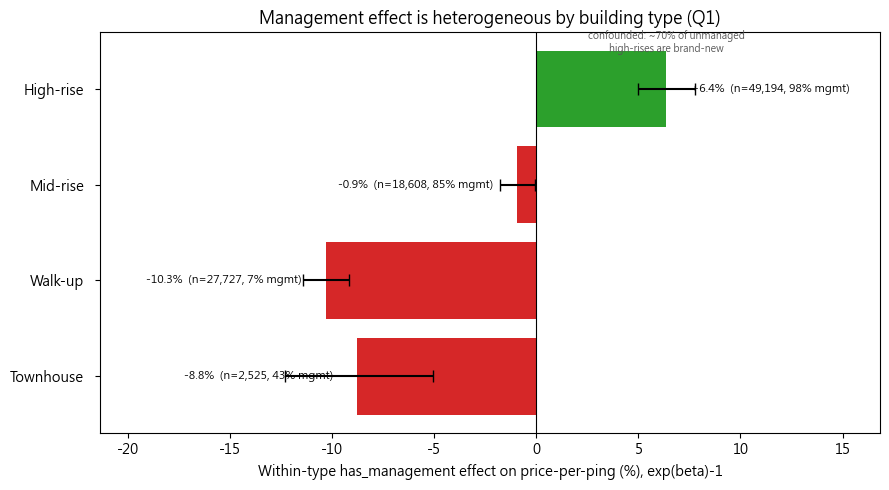

saved management_by_type.png


In [24]:
# Secondary (Q1, honest): has_management effect within each building type.
order = ['透天厝', '公寓(5樓含以下無電梯)', '華廈(10層含以下有電梯)', '住宅大樓(11層含以上有電梯)']
eng_labels = ['Townhouse', 'Walk-up', 'Mid-rise', 'High-rise']
wd = within_df.set_index('building_type').reindex(order)
effects = (wd['effect'] * 100).tolist()
err_low = ((wd['effect'] - wd['ci_low']) * 100).tolist()
err_high = ((wd['ci_high'] - wd['effect']) * 100).tolist()
colors = ['#d62728' if e < 0 else '#2ca02c' for e in effects]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(eng_labels, effects, xerr=[err_low, err_high], color=colors, capsize=4)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Within-type has_management effect on price-per-ping (%), exp(beta)-1')
ax.set_title('Management effect is heterogeneous by building type (Q1)')
ax.tick_params(axis='y', pad=8)
for i, bt in enumerate(order):
    ax.text(effects[i] + (1.2 if effects[i] >= 0 else -1.2), i,
            f"{effects[i]:+.1f}%  (n={int(wd['N'].iloc[i]):,}, {wd['managed_pct'].iloc[i]:.0f}% mgmt)",
            va='center', ha='left' if effects[i] >= 0 else 'right', fontsize=8)
ax.text(effects[3], 3.35, 'confounded: ~70% of unmanaged\nhigh-rises are brand-new', fontsize=7,
        ha='center', va='bottom', color='#555')
ax.margins(x=0.45)
plt.tight_layout()
plt.savefig(f'{ASSETS_DIR}/management_by_type.png', dpi=150)
plt.show()
print('saved management_by_type.png')


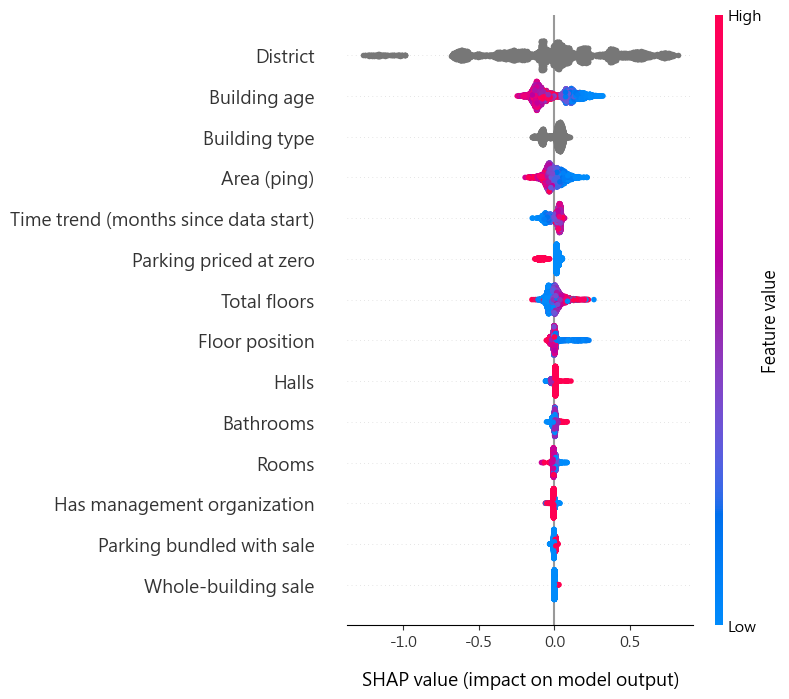

saved shap_summary.png


In [25]:
# Plain-English feature labels for the dashboard's non-technical audience --
# display only, doesn't touch shap_values/feature_cols/ranking anywhere else
# in the notebook (mean_abs_shap above still indexes by the raw column name).
FEATURE_LABELS_EN = {
    'district': 'District',
    'building_age': 'Building age',
    'building_type': 'Building type',
    'area_ping': 'Area (ping)',
    'months_since_start': 'Time trend (months since data start)',
    'parking_price_is_zero_int': 'Parking priced at zero',
    'total_floors': 'Total floors',
    'floor_ratio': 'Floor position',
    'halls': 'Halls',
    'baths': 'Bathrooms',
    'rooms': 'Rooms',
    'has_management_int': 'Has management organization',
    'bundled_parking_int': 'Parking bundled with sale',
    'whole_building_int': 'Whole-building sale',
}
shap_feature_labels = [FEATURE_LABELS_EN[c] for c in feature_cols]

fig, ax = plt.subplots(figsize=(8, 6))
shap.summary_plot(shap_values, shap_sample, feature_names=shap_feature_labels, show=False)
ax = plt.gca()
ax.set_xlabel(ax.get_xlabel(), labelpad=15)
plt.tight_layout()
plt.savefig(f'{ASSETS_DIR}/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved shap_summary.png')

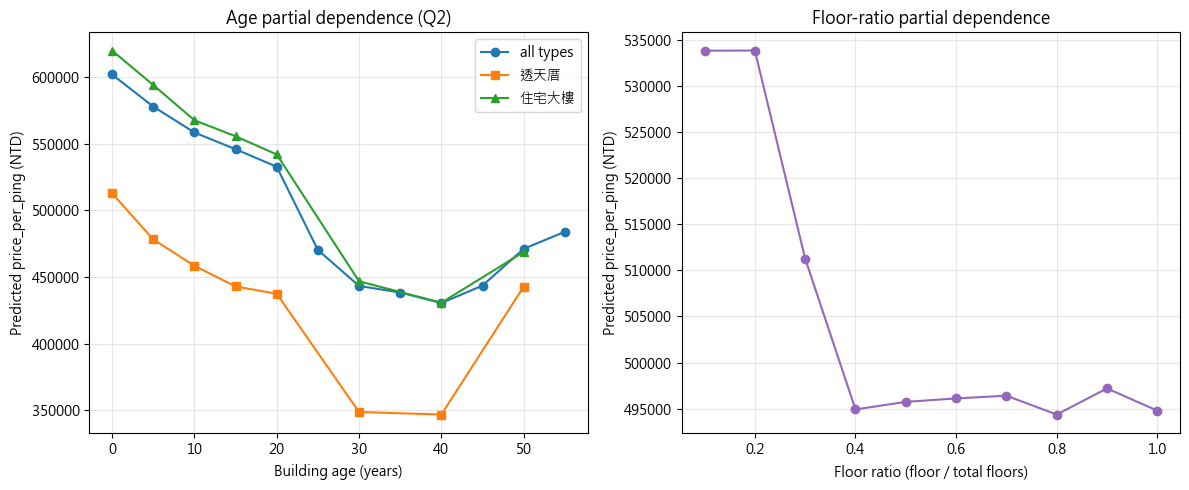

saved age_floor_partial_dependence.png


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ages_arr, prices_arr = zip(*overall_pd)
axes[0].plot(ages_arr, prices_arr, marker='o', label='all types')
t_ages, t_prices = zip(*townhouse_pd)
h_ages, h_prices = zip(*highrise_pd)
axes[0].plot(t_ages, t_prices, marker='s', label='透天厝')
axes[0].plot(h_ages, h_prices, marker='^', label='住宅大樓')
axes[0].set_xlabel('Building age (years)')
axes[0].set_ylabel('Predicted price_per_ping (NTD)')
axes[0].set_title('Age partial dependence (Q2)')
axes[0].legend()
axes[0].grid(alpha=0.3)

fr_x, fr_y = zip(*floor_pd)
axes[1].plot(fr_x, fr_y, marker='o', color='#9467bd')
axes[1].set_xlabel('Floor ratio (floor / total floors)')
axes[1].set_ylabel('Predicted price_per_ping (NTD)')
axes[1].set_title('Floor-ratio partial dependence')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS_DIR}/age_floor_partial_dependence.png', dpi=150)
plt.show()
print('saved age_floor_partial_dependence.png')


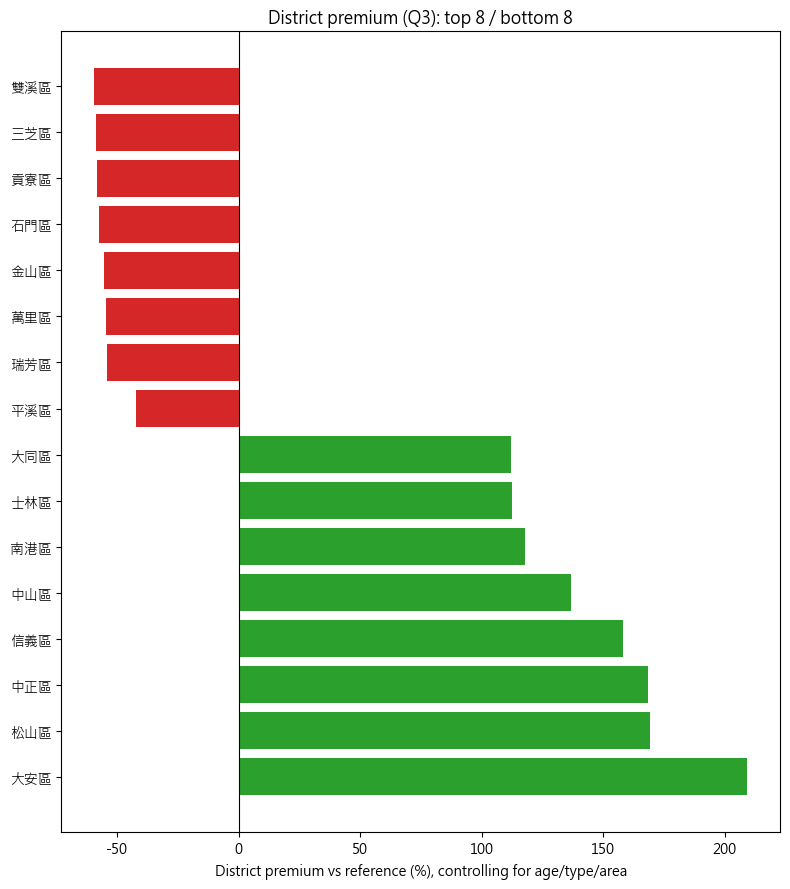

saved district_premium.png


In [27]:
fig, ax = plt.subplots(figsize=(8, 9))
top_bottom = pd.concat([district_coefs.head(8), district_coefs.tail(8)])
colors = ['#2ca02c' if v >= 0 else '#d62728' for v in top_bottom]
ax.barh([c.replace('district_', '') for c in top_bottom.index], top_bottom.values * 100, color=colors)
ax.set_xlabel('District premium vs reference (%), controlling for age/type/area')
ax.set_title('District premium (Q3): top 8 / bottom 8')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(f'{ASSETS_DIR}/district_premium.png', dpi=150)
plt.show()
print('saved district_premium.png')


### Export underlying numbers as JSON (for the dashboard's interactive charts)

The Streamlit dashboard renders these same findings as interactive Plotly
charts instead of static PNGs. To guarantee it shows the **exact same
numbers** this notebook produced -- not a recomputed approximation -- the
underlying data is exported here, once, as the single source of truth. The
dashboard only loads and plots this JSON; it never re-fits a model to
reproduce these specific figures.

In [28]:
import json

# Export ALL district coefficients (not just top/bottom 8) so the dashboard
# can slice its own top-N/bottom-N without touching the notebook again --
# same already-computed district_coefs, no recomputation, just more rows.
district_premium_data = [
    {'district': c.replace('district_', ''), 'effect_pct': float(v * 100)}
    for c, v in district_coefs.items()
]

management_by_type_data = [
    {
        'building_type': order[i],
        'label': eng_labels[i],
        'effect_pct': float(wd['effect'].iloc[i] * 100),
        'ci_low_pct': float(wd['ci_low'].iloc[i] * 100),
        'ci_high_pct': float(wd['ci_high'].iloc[i] * 100),
        'n': int(wd['N'].iloc[i]),
        'managed_pct': float(wd['managed_pct'].iloc[i]),
    }
    for i in range(len(order))
]

age_floor_data = {
    'overall': [{'age': a, 'price_per_ping': float(p)} for a, p in overall_pd],
    'townhouse': [{'age': a, 'price_per_ping': float(p)} for a, p in townhouse_pd],
    'highrise': [{'age': a, 'price_per_ping': float(p)} for a, p in highrise_pd],
    'floor_ratio': [{'floor_ratio': r, 'price_per_ping': float(p)} for r, p in floor_pd],
}

with open(f'{ASSETS_DIR}/district_premium_data.json', 'w', encoding='utf-8') as f:
    json.dump(district_premium_data, f, ensure_ascii=False, indent=2)
with open(f'{ASSETS_DIR}/management_by_type_data.json', 'w', encoding='utf-8') as f:
    json.dump(management_by_type_data, f, ensure_ascii=False, indent=2)
with open(f'{ASSETS_DIR}/age_floor_data.json', 'w', encoding='utf-8') as f:
    json.dump(age_floor_data, f, ensure_ascii=False, indent=2)

print('saved district_premium_data.json, management_by_type_data.json, age_floor_data.json')


saved district_premium_data.json, management_by_type_data.json, age_floor_data.json
